# Caso práctico: procesamiento y análisis de series temporales

La siguiente BBDD contiene información sobre la la población registrada por municipio es España desde 1996.

Lee y prepara los datos:
- Lectura de datos
- Formateo de columnas
- Homogeinización de la frecuencia muestral
- Calidad de los datos
- Tratamiento de missings


Realiza un análisis demográfico de las provincias de Euskadi y Navarra. Compara las diferentes evoluciones entre sí. ¿Existe alguna correlación?


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("ine_poblacion.csv", sep=";", dtype=str)
print(df.shape)
df.head()

(4134, 4)


,Provincias,Sexo,Periodo,Total
0,Total,Total,2021,47.385.107
1,Total,Total,2020,47.450.795
2,Total,Total,2019,47.026.208
3,Total,Total,2018,46.722.980
4,Total,Total,2017,46.572.132


In [3]:
df.columns = ["provincia", "sexo", "periodo", "poblacion"]

# "47.385.107" -> 47385107 ; las celdas vacías ("") pasan a NaN
df["poblacion"] = pd.to_numeric(df["poblacion"].str.replace(".", "", regex=False), errors="coerce")
df["periodo"] = pd.to_datetime(df["periodo"], format="%Y")

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4134 entries, 0 to 4133
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   provincia  4134 non-null   object        
 1   sexo       4134 non-null   object        
 2   periodo    4134 non-null   datetime64[ns]
 3   poblacion  3975 non-null   float64       
dtypes: datetime64[ns](1), float64(1), object(2)
memory usage: 129.3+ KB


In [4]:
# Una columna por (provincia, sexo) y un punto por año, con frecuencia regular
tabla = (df.set_index(["periodo", "provincia", "sexo"])["poblacion"]
           .unstack(["provincia", "sexo"])
           .sort_index()
           .asfreq("YS"))

print(tabla.index.freq, "|", tabla.index.min().year, "->", tabla.index.max().year, "|", len(tabla), "años")

<YearBegin: month=1> | 1996 -> 2021 | 26 años


In [6]:
print("Duplicados:", df.duplicated(["provincia", "sexo", "periodo"]).sum())
print("Valores <= 0:", (df["poblacion"] <= 0).sum())
print("Provincias (incl. Total):", df["provincia"].nunique())

nulos = df["poblacion"].isna().groupby(df["periodo"].dt.year).sum()
print("Missings por año:\n", nulos[nulos > 0])

# Coherencias internas
t = tabla.xs("Total", axis=1, level="sexo")
h = tabla.xs("Hombres", axis=1, level="sexo")
m = tabla.xs("Mujeres", axis=1, level="sexo")
print("max |Hombres + Mujeres - Total|:", (h + m - t).abs().max().max())
print("max |suma provincias - Total nacional|:",
      (t.drop(columns="Total").sum(axis=1, min_count=52) - t["Total"]).abs().max())
# Solo falta 1997 (en todas las provincias y sexos). Es un año entre dos observados,
# la población evoluciona de forma suave, así que se interpola linealmente en el tiempo.
tabla_i = tabla.interpolate(method="time")
print("Missings tras interpolar:", tabla_i.isna().sum().sum())

Duplicados: 0
Valores <= 0: 0
Provincias (incl. Total): 53
Missings por año:
 periodo
1997    159
Name: poblacion, dtype: int64
max |Hombres + Mujeres - Total|: 0.0
max |suma provincias - Total nacional|: 0.0
Missings tras interpolar: 0


## Seleccion Euskadi y Navarra

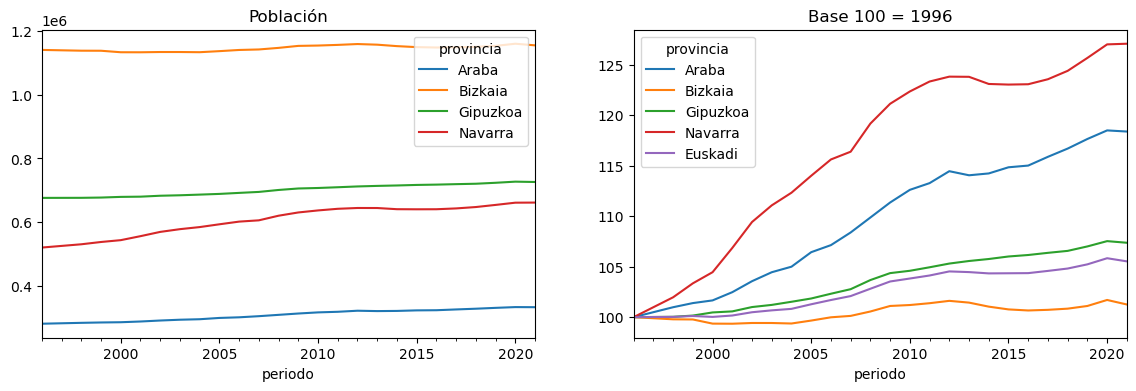

,1996,2021,crec_%,CAGR_%,max,año_max
provincia,,,,,,
Araba,281821.0,333626.0,18.38,0.68,333940.0,2020
Bizkaia,1140026.0,1154334.0,1.26,0.05,1159443.0,2020
Gipuzkoa,676208.0,726033.0,7.37,0.28,727121.0,2020
Navarra,520574.0,661537.0,27.08,0.96,661537.0,2021
Euskadi,2098055.0,2213993.0,5.53,0.22,2220504.0,2020


In [7]:
t = tabla_i.xs("Total", axis=1, level="sexo")

codigos = {"01": "Araba", "48": "Bizkaia", "20": "Gipuzkoa", "31": "Navarra"}
cols = {c: codigos[c[:2]] for c in t.columns if c[:2] in codigos}
prov = list(codigos.values())

pob = t[list(cols)].rename(columns=cols)[prov]
pob["Euskadi"] = pob[["Araba", "Bizkaia", "Gipuzkoa"]].sum(axis=1)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
pob[prov].plot(ax=ax[0], title="Población")
(pob / pob.iloc[0] * 100).plot(ax=ax[1], title="Base 100 = 1996")
plt.show()

n = len(pob) - 1
resumen = pd.DataFrame({
    "1996": pob.iloc[0],
    "2021": pob.iloc[-1],
    "crec_%": (pob.iloc[-1] / pob.iloc[0] - 1) * 100,
    "CAGR_%": ((pob.iloc[-1] / pob.iloc[0]) ** (1 / n) - 1) * 100,
    "max": pob.max(),
    "año_max": pob.idxmax().dt.year,
}).round(2)
resumen

## Composicion poe sexo

In [8]:
def serie_sexo(sexo):
    x = tabla_i.xs(sexo, axis=1, level="sexo")
    return x[list(cols)].rename(columns=cols)[prov]

pct_mujeres = serie_sexo("Mujeres") / serie_sexo("Total") * 100
pct_mujeres.iloc[[0, -1]].round(2)

provincia,Araba,Bizkaia,Gipuzkoa,Navarra
periodo,,,,
1996-01-01,50.34,51.29,50.92,50.49
2021-01-01,50.77,51.71,51.14,50.50


## correlación entre provincias

Correlación de niveles (engañosa: todas las series tienen tendencia):
provincia  Araba  Bizkaia  Gipuzkoa  Navarra
provincia                                   
Araba      1.000    0.870     0.997    0.978
Bizkaia    0.870    1.000     0.873    0.837
Gipuzkoa   0.997    0.873     1.000    0.963
Navarra    0.978    0.837     0.963    1.000

Correlación de las tasas de crecimiento anual:
provincia  Araba  Bizkaia  Gipuzkoa  Navarra
provincia                                   
Araba      1.000    0.737     0.628    0.633
Bizkaia    0.737    1.000     0.734    0.526
Gipuzkoa   0.628    0.734     1.000    0.469
Navarra    0.633    0.526     0.469    1.000

Igual, sin los años que dependen del dato interpolado (1997 y 1998):
provincia  Araba  Bizkaia  Gipuzkoa  Navarra
provincia                                   
Araba      1.000    0.732     0.631    0.639
Bizkaia    0.732    1.000     0.733    0.535
Gipuzkoa   0.631    0.733     1.000    0.509
Navarra    0.639    0.535     0.509    1.000


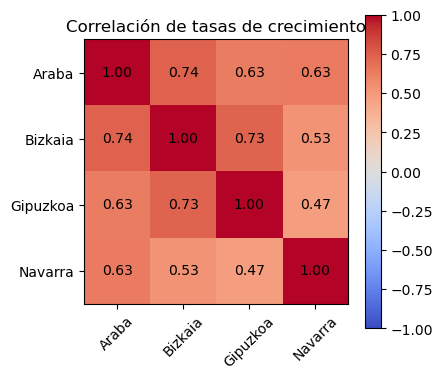

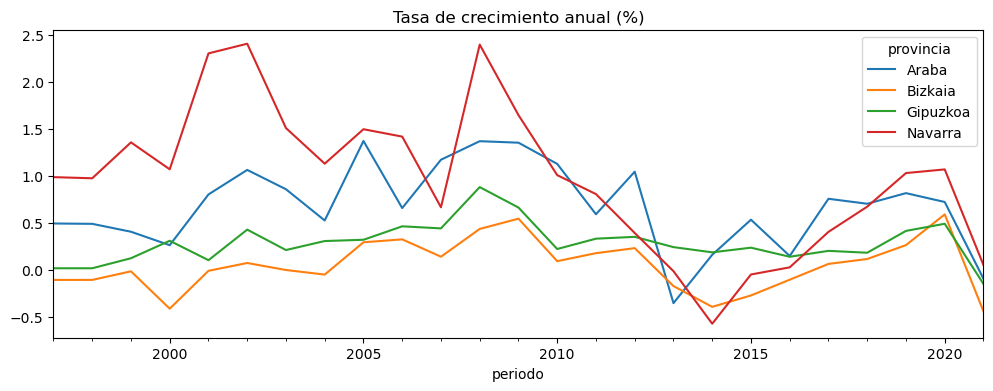

In [9]:
crec = pob[prov].pct_change().dropna() * 100     # tasa de crecimiento anual (%)

print("Correlación de niveles (engañosa: todas las series tienen tendencia):")
print(pob[prov].corr().round(3))

print("\nCorrelación de las tasas de crecimiento anual:")
print(crec.corr().round(3))

print("\nIgual, sin los años que dependen del dato interpolado (1997 y 1998):")
print(crec.loc[~crec.index.year.isin([1997, 1998])].corr().round(3))

def heatmap(corr, titulo):
    fig, ax = plt.subplots(figsize=(4.5, 4))
    im = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
    ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45)
    ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.index)
    for i in range(len(corr)):
        for j in range(len(corr)):
            ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")
    ax.set_title(titulo)
    fig.colorbar(im)
    plt.tight_layout()
    plt.show()

heatmap(crec.corr(), "Correlación de tasas de crecimiento")
crec.plot(figsize=(12, 4), title="Tasa de crecimiento anual (%)")
plt.show()